# Carga de Datos

In [1]:
#Obtención de la data
from LHC import experiment_CMS
experiment_CMS(num_img=500, size=64, zip_name="CERN_dataset")

Dataset generado con 500 imágenes por clase.
Archivo comprimido: CERN_dataset.zip


In [2]:
import os
import zipfile
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def cargar_datos(zip_path="CERN_dataset.zip", carpeta_salida="CERN_datos"):
    #1. Proceso para descomprimir el archivo ZIP
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(carpeta_salida)
    X = []
    y = []
    #2. Recorrer las carpetas con las imagenes
    for clase in os.listdir(carpeta_salida):
        clase_path = os.path.join(carpeta_salida, clase)
        if os.path.isdir(clase_path):
            for img_name in os.listdir(clase_path):
                img_path = os.path.join(clase_path, img_name)

                # 3. Procedimiento para cargar imagenes en escala de grises
                img = Image.open(img_path).convert("L")

                #Normalizar las matrices
                #X solo tiene puntos en negro (0) y en blanco (255)
                
                X.append(np.array(img)/255)
                y.append(clase)  # etiqueta = nombre de la carpeta
                
    X = np.array(X)
    return X, y

# Exploración Inicial de Datos

## Dimensiones de los Datos

In [3]:
X, y = cargar_datos("CERN_dataset.zip")
print(f"Se cargaron {len(X)} imágenes.")
print(f"Clases encontradas:")
print(np.unique(y, return_counts=True))
print("Dimensiones de las imágenes:", X.shape)

Se cargaron 3000 imágenes.
Clases encontradas:
(array(['electron', 'muon', 'neutrino', 'proton', 'quark', 'tau'],
      dtype='<U8'), array([500, 500, 500, 500, 500, 500]))
Dimensiones de las imágenes: (3000, 64, 64)


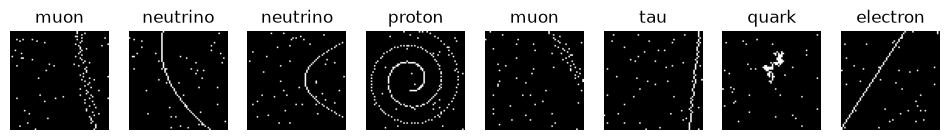

In [4]:
def mostrar_imagenes(X, y, n):
    indices = np.random.choice(len(X), n, replace=False)  # elegir imagen aleatoriamente
    plt.figure(figsize=(12, 4))

    for i, idx in enumerate(indices):
        plt.subplot(1, n, i+1)
        plt.imshow(X[idx], cmap="gray")
        plt.title(y[idx])
        plt.axis("off")
    plt.show()

mostrar_imagenes(X, y, 8)

## Matrices Normalizadas

Las instancias de X se normalizaron durante la carga de datos

In [5]:
np.unique(X)

array([0., 1.])

## Reducción de Dimensionalidad 

In [6]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder

# Pasar las matrices a bidimensionales
X_bi = X.reshape(len(X), 64 * 64)

# Codificar las clases para que puedan ser leidas por sklearn
le = LabelEncoder()
y_num = le.fit_transform(y)
nombres_clases = le.classes_

# Reducir las dimensiones hasta conservar el 95% de la varianza de los datos (no perder información de su distribución)
pca = PCA(n_components = 0.95)
X_r = pca.fit_transform(X_bi)


## Partición de Datos

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_r,
                                                    y_num,
                                                    test_size=0.30,
                                                    random_state=40,
                                                    stratify=y_num)

In [8]:
print(np.unique(y_test, return_counts=True))

(array([0, 1, 2, 3, 4, 5]), array([150, 150, 150, 150, 150, 150]))


# Modelo SVM

## SVM

/home/NicLop/Nic/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Kernel:  linear
              precision    recall  f1-score   support

           0       0.36      0.40      0.38       150
           1       0.29      0.27      0.28       150
           2       0.40      0.39      0.39       150
           3       1.00      1.00      1.00       150
           4       0.97      0.95      0.96       150
           5       0.35      0.34      0.35       150

    accuracy                           0.56       900
   macro avg       0.56      0.56      0.56       900
weighted avg       0.56      0.56      0.56       900



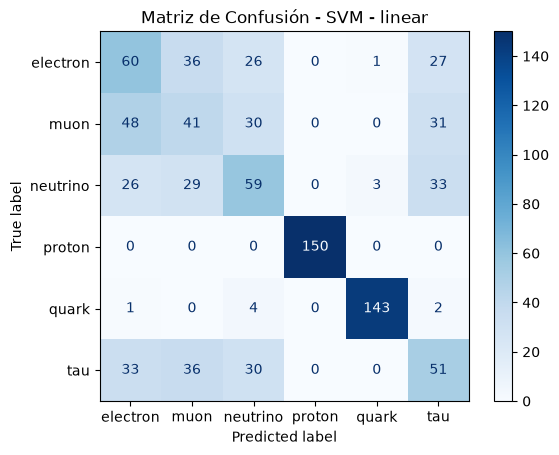

/home/NicLop/Nic/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Kernel:  rbf
              precision    recall  f1-score   support

           0       0.37      0.30      0.33       150
           1       0.32      0.26      0.29       150
           2       0.49      0.50      0.49       150
           3       1.00      1.00      1.00       150
           4       1.00      0.95      0.98       150
           5       0.39      0.55      0.46       150

    accuracy                           0.59       900
   macro avg       0.59      0.59      0.59       900
weighted avg       0.59      0.59      0.59       900



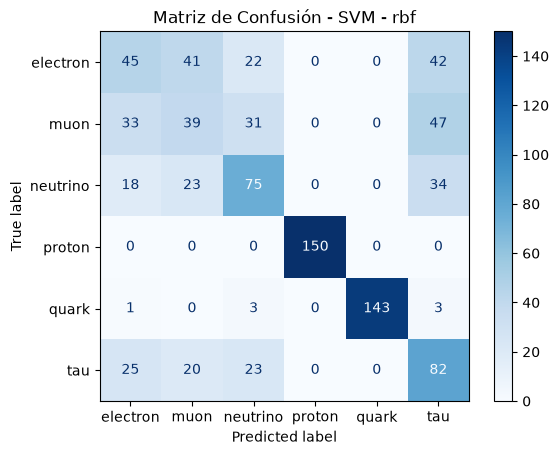

/home/NicLop/Nic/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Kernel:  poly
              precision    recall  f1-score   support

           0       0.34      0.45      0.38       150
           1       0.21      0.81      0.33       150
           2       1.00      0.01      0.01       150
           3       0.00      0.00      0.00       150
           4       1.00      0.76      0.86       150
           5       0.00      0.00      0.00       150

    accuracy                           0.34       900
   macro avg       0.42      0.34      0.27       900
weighted avg       0.42      0.34      0.27       900



/home/NicLop/Nic/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/NicLop/Nic/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/NicLop/Nic/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


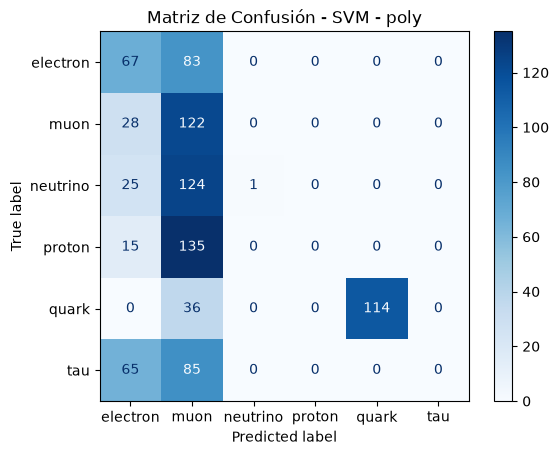

In [9]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


kernels = ['linear', 'rbf', 'poly']
#guardar el modelo de cada kernel
modelos = {} 

for kernel in kernels:
    model = SVC(kernel=kernel, C=5, probability=True) #probability necesario para la curva ROC
    model.fit(X_train, y_train)
    modelos[kernel] = model
    y_pred = model.predict(X_test)
    
    print("Kernel: ", kernel)
    print(classification_report(y_test, y_pred))

    # Calcular la matriz matemática
    cm = confusion_matrix(y_test, y_pred)
    
    # Renderizar la matriz visualmente
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=nombres_clases)
    disp.plot(cmap='Blues', values_format='d')
    plt.title(f"Matriz de Confusión - SVM - {kernel}")
    plt.show()

## Curva ROC

Esta curva aplica para problemas de clasificación binaria, para implementarla en este caso hay que realizar una curva para cada clase.

Esto nos daría información de la capacidad del modelo para discriminar a esa partícula en específico de todas las demás.

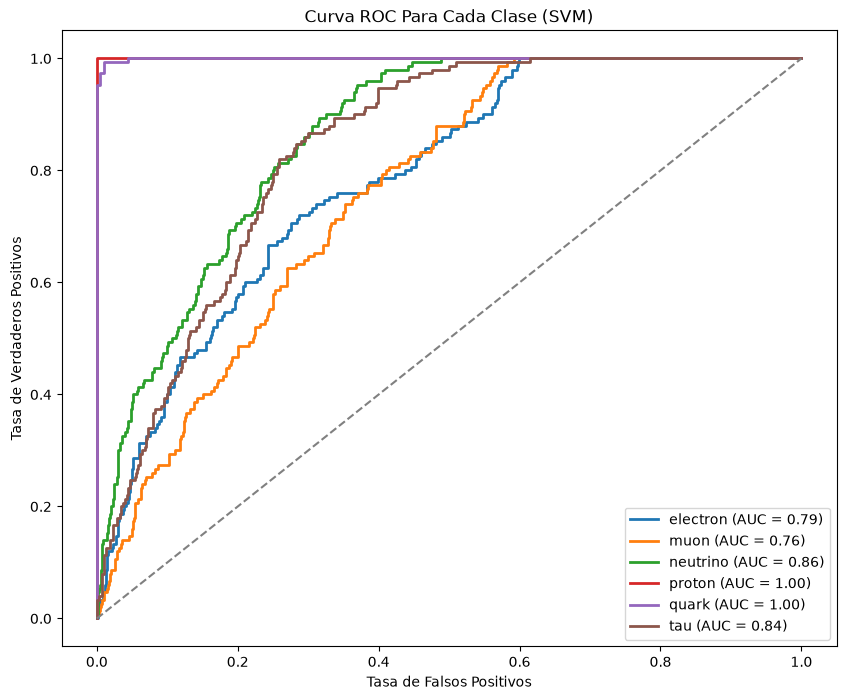

In [10]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

# Binarizar las clases
# 1 si pertenece a la clase, 0 si pertenece a cualquier otra
y_test_bin = label_binarize(y_test, classes=[0, 1, 2, 3, 4, 5])

# Asignarle un punta probabilistico a cada instancia para hacer la curva
y_score = modelos['rbf'].predict_proba(X_test)

plt.figure(figsize=(10, 8))

# Calcular y graficar la curva ROC para cada partícula respecto a las demas
for i in range(6):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'{nombres_clases[i]} (AUC = {roc_auc:.2f})')

#linea para el caso de discriminación aleatoria
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')

plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC Para Cada Clase (SVM)')
plt.legend(loc="lower right")
plt.show()

# Modelo de Regresión Logística

# Regresión Logística

In [11]:
from sklearn.linear_model import LogisticRegression

#Entrenar el modelo
model2=LogisticRegression(C=5)
model2.fit(X_train, y_train)
y_pred_L = model2.predict(X_test)

#Parametros encontrados
print("Parametros óptimos conseguidos:")
print("Pesos: ", model2.coef_)
print("Bias: ", model2.intercept_)

Parametros óptimos conseguidos:
Pesos:  [[-9.17853528e-01 -1.43459356e+00  1.13138176e+00 ...  3.02430130e-01
  -5.80077942e-02  4.64947560e-02]
 [-6.29301136e-01 -2.19347738e+00  6.83317960e-01 ... -3.01277352e-01
   1.47341907e-03  2.22990289e-01]
 [-5.12198966e-01 -4.62613090e-01  9.86457396e-02 ... -2.27579504e-01
  -3.50313499e-02  6.57652658e-03]
 [-1.00368915e+00  4.12566638e+00 -1.90774150e+00 ... -1.57473882e-03
   3.82953448e-02 -2.60361205e-02]
 [ 4.24986606e+00  4.40217220e-01  6.14392926e-02 ...  4.01509778e-02
  -1.11089332e-02 -6.79311364e-02]
 [-1.18682328e+00 -4.75199572e-01 -6.70432528e-02 ...  1.87850487e-01
   6.43793136e-02 -1.82094314e-01]]
Bias:  [ 0.11054906 -0.0383468   0.75955928 -1.0106179  -0.53981278  0.71866914]


In [12]:
print(model2.coef_.shape)
print(model2.intercept_.shape)

(6, 1939)
(6,)


## Matriz de Confusión

              precision    recall  f1-score   support

           0       0.32      0.33      0.33       150
           1       0.31      0.30      0.30       150
           2       0.37      0.36      0.36       150
           3       0.99      0.97      0.98       150
           4       0.98      0.96      0.97       150
           5       0.32      0.33      0.32       150

    accuracy                           0.54       900
   macro avg       0.55      0.54      0.55       900
weighted avg       0.55      0.54      0.55       900



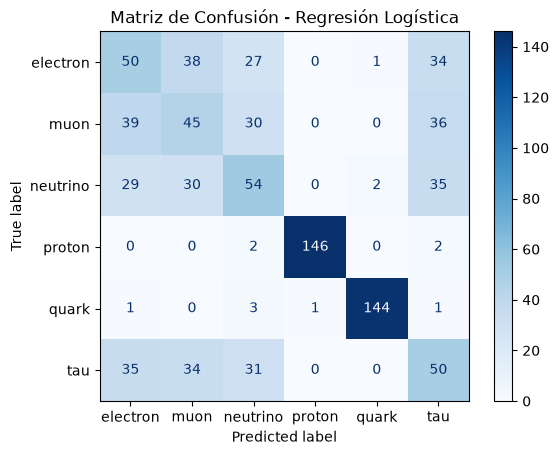

In [13]:
print(classification_report(y_test, y_pred_L))

# Calcular la matriz matemática
cm = confusion_matrix(y_test, y_pred_L)

# Renderizar la matriz visualmente
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=nombres_clases)
disp.plot(cmap='Blues', values_format='d')
plt.title("Matriz de Confusión - Regresión Logística")
plt.show()

## Curva ROC

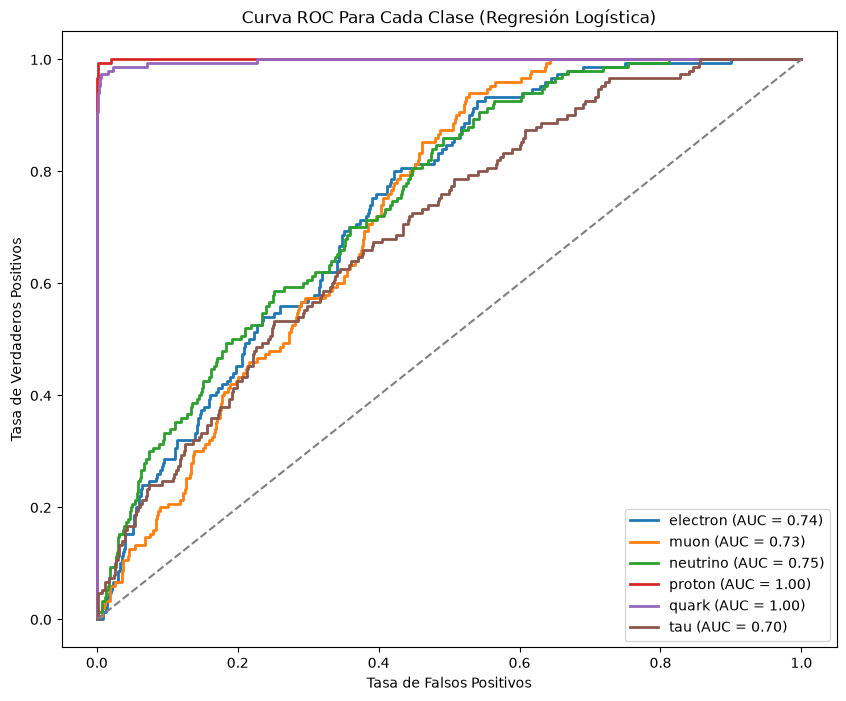

In [14]:
y_test_bin_L = label_binarize(y_test, classes=[0, 1, 2, 3, 4, 5])

# Asignarle un punta probabilistico a cada instancia para hacer la curva
y_score_L = model2.predict_proba(X_test)

plt.figure(figsize=(10, 8))

# Calcular y graficar la curva ROC para cada partícula respecto a las demas
for i in range(6):
    fpr, tpr, _ = roc_curve(y_test_bin_L[:, i], y_score_L[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'{nombres_clases[i]} (AUC = {roc_auc:.2f})')

#linea para el caso de discriminación aleatoria
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')

plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC Para Cada Clase (Regresión Logística)')
plt.legend(loc="lower right")
plt.show()

# Discución y Conclusiones

electron


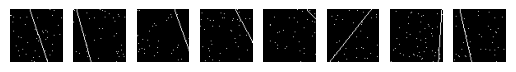

muon


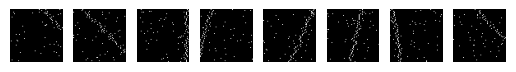

neutrino


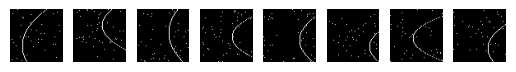

proton


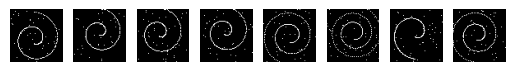

quark


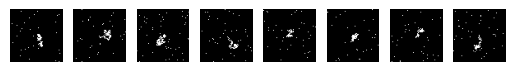

tau


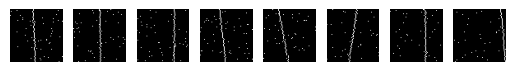

In [15]:
import random

def ej_clase(X, y, n_ej):
    for i in range(6):
        clase = np.where(y_num == i)[0]

        print(nombres_clases[i])
        for j in range(n_ej):
            idx = random.choice(clase)
            
            plt.subplot(1, n_ej, j+1)
            plt.imshow(X[idx], cmap="gray")
            plt.axis("off")
        plt.show()


ej_clase(X, y, n_ej = 8)


### Curva ROC (Capacidad de Distinción)

- Los modelos clasifican perfectamente las partículas quark y protones. Esto probablemente se debe a que poseen trayectorias notablemente distintas al resto de patículas, causando que la distribución de sus datos sea fácilmente diferenciable de las demas.
- Los modelos presentan el menor desempeño al momento de clasificar electrones y muones. Puede deberse a que:
    - Se puede observar que en algunas imágenes no se registró apropiadamente la trayectoria de las partículas, detectándose únicamente ruido.
    - La trayectoria de los muones está muy dispersa, lo que pudo favorecer a que fueran confundidas con ruido
    - Las trayectorias de las partículas tau y de los electrones son muy similares, dificultando su distinción
- La regresión logística tiene una baja capacidad de discriminación para todas las clases que no sean quark y protones. Como se observa en la matriz de confusión las instancias las reparte entre estas clases y basándose en el AUC las decisiones son cercanas a un juicio aleatorio (AUC=0.5) 

### Desempeño de los Kernel de SVM

- El kernel rbf es el que presenta el mejor desempeño a la hora de clasificar las instancias de testeo.
    - Resultados perfectos para los quark y protones
    - Desempeño parcial para tau y neutrinos
    - El modelo prácticamente no clasifica muones y electrones, los confunde entre sí o con neutrinos y partículas tau
- El kernel polinómico es completamente inefectivo, solo logra clasificar correctamente algunas instancias de quarks, el resto los clasifica todos como electrones o muones.
- Ignorando el kernel polinómico, los kernel rbf y lineal poseen un desempeño similar; y basándose en la exactitud la regresión logística no se aleja mucho. La similitud en el desempeño de los modelos puede indicar que para incrementar las predicciones correctas se requiere una mejora en los datos (más características) y no en un cambio de modelo.

### Aspectos a Mejorar

- Dada la similitud entre las trayectorias de muones, electrones y tau, se facilita la aparición de fallas a la hora de clasificarlas. Se requiere añadir algunas características extra que facilite la distinción.
- La inefectividad del kernel polinómico no necesariamente sugiere su incapacidad de discriminación de las clases. Es probable que su bajo desempeño se deba a una elección inadecuada de hiperparámetros del modelo (como el parámetro de regularización C, o gamma), la cual se realizó de manera arbitraria. Realizar una selección efectiva de estas características puede mejorar sus resultados